<a href="https://colab.research.google.com/github/ushank-rajeshirke/LocalRepo/blob/main/MNIST_Classifier_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron # used for classification task

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential # Sequential lets build a neural network layer by layer in Keras.

from tensorflow.keras.layers import Dense # Dense makes the final prediction
from tensorflow .keras.layers import Conv2D # Conv2D extract features
from tensorflow.keras.layers import Flatten # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D # Maxpooling2D reduce size
from tensorflow.keras.layers import Dropout # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical # converts numeric class labels into one-hot encoded format for training classification



In [15]:
df = pd.read_csv("/content/drive/MyDrive/csv_files/mnist_train.csv")
df_test = pd.read_csv("/content/drive/MyDrive/csv_files/mnist_test.csv")

In [16]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [17]:
df.shape

(60000, 785)

In [18]:
df.columns

Index(['label', '1x1', '1x2', '1x3', '1x4', '1x5', '1x6', '1x7', '1x8', '1x9',
       ...
       '28x19', '28x20', '28x21', '28x22', '28x23', '28x24', '28x25', '28x26',
       '28x27', '28x28'],
      dtype='object', length=785)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 359.3 MB


In [20]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,0
28x25,0
28x26,0
28x27,0


In [21]:
#Preprocess
X_train = df.drop("label", axis=1).values
y_train = df["label"].values
X_test = df_test.drop("label", axis=1).values
y_test = df_test["label"].values

In [ ]:
# Convert the value betweeen 0 and 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0


In [28]:
# Convert into array form for images
X_train_img = X_train.reshape(-1,28,28)
X_test_img = X_test.reshape(-1,28,28)

In [29]:
y_train_cat = to_categorical(y_train,10)
y_test_cat = to_categorical(y_test,10)

In [33]:
model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10, activation="softmax")
])


In [35]:
model.compile(optimizer = "sgd", loss ="categorical_crossentropy", metrics =["accuracy"])

In [36]:
history = model.fit(X_train_img , y_train_cat , epochs = 5, batch_size=32,validation_data=(X_test_img, y_test_cat),verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8441 - loss: 319.7794 - val_accuracy: 0.8679 - val_loss: 240.3600
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8687 - loss: 261.9379 - val_accuracy: 0.8750 - val_loss: 241.1101
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8736 - loss: 253.7820 - val_accuracy: 0.8927 - val_loss: 215.8783
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8763 - loss: 247.7401 - val_accuracy: 0.8805 - val_loss: 258.0124
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8774 - loss: 243.4186 - val_accuracy: 0.8912 - val_loss: 222.2464


In [37]:
loss , acc = model.evaluate(X_test_img, y_test_cat,verbose=1)
print("Loss:", loss)
print("Accuracy:", acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8912 - loss: 222.2464
Loss: 222.24635314941406
Accuracy: 0.8912000060081482


In [40]:
#ANN
ann_model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation ="relu"),
    Dense(64, activation ="relu"),
    Dense(10, activation ="softmax")
])

In [43]:
ann_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics =["accuracy"])

In [44]:
# To fix the side-by-side visualization error, use 'model' (your Perceptron equivalent) instead of 'Perceptron' class
show_side_by_side([model, ann_model, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7657 - loss: 6.2497 - val_accuracy: 0.8727 - val_loss: 1.3918
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8828 - loss: 1.1036 - val_accuracy: 0.9009 - val_loss: 0.6857
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9162 - loss: 0.6323 - val_accuracy: 0.9166 - val_loss: 0.6928
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9339 - loss: 0.4419 - val_accuracy: 0.9480 - val_loss: 0.2607
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9431 - loss: 0.3770 - val_accuracy: 0.9534 - val_loss: 0.2748


In [45]:
loss_ann, acc_ann = ann_model.evaluate(X_test_img,y_test_cat,verbose=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9534 - loss: 0.2748


NOW CNN STARTS

In [47]:
X_train_cnn = X_train.reshape(-1,28,28,1)
X_test_cnn = X_test.reshape(-1,28,28,1)

In [49]:
cnn = Sequential([
    Conv2D(32,kernel_size=(3,3), activation = "relu", input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3),activation ="relu"),
     MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")


])

In [52]:
cnn.compile(optimizer="adam",loss ="categorical_crossentropy", metrics =["accuracy"])

In [55]:
history_cnn =cnn.fit(X_train_cnn,y_train_cat, epochs= 5,batch_size=32, validation_data=(X_test_cnn,y_test_cat),verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9819 - loss: 0.0642 - val_accuracy: 0.9875 - val_loss: 0.0389
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9824 - loss: 0.0632 - val_accuracy: 0.9871 - val_loss: 0.0449
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 18ms/step - accuracy: 0.9843 - loss: 0.0538 - val_accuracy: 0.9903 - val_loss: 0.0382
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.9856 - loss: 0.0517 - val_accuracy: 0.9906 - val_loss: 0.0372
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.9855 - loss: 0.0505 - val_accuracy: 0.9882 - val_loss: 0.0470


In [56]:
acc_cnn = cnn.evaluate(X_test_cnn,y_test_cat,verbose=1)


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9882 - loss: 0.0470


In [57]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()


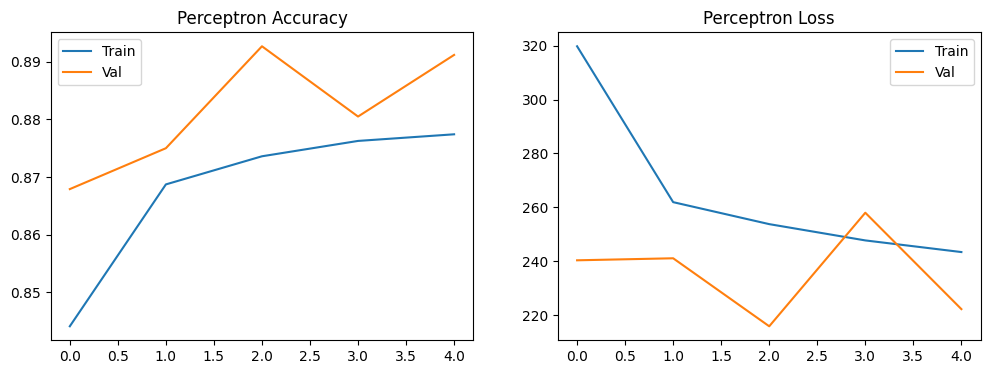

In [59]:

plot_training(history, "Perceptron")

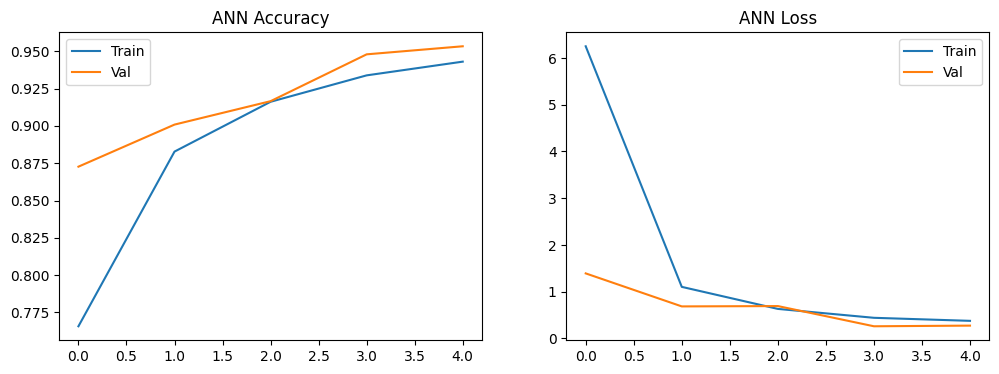

In [60]:
plot_training(history_ann, "ANN")

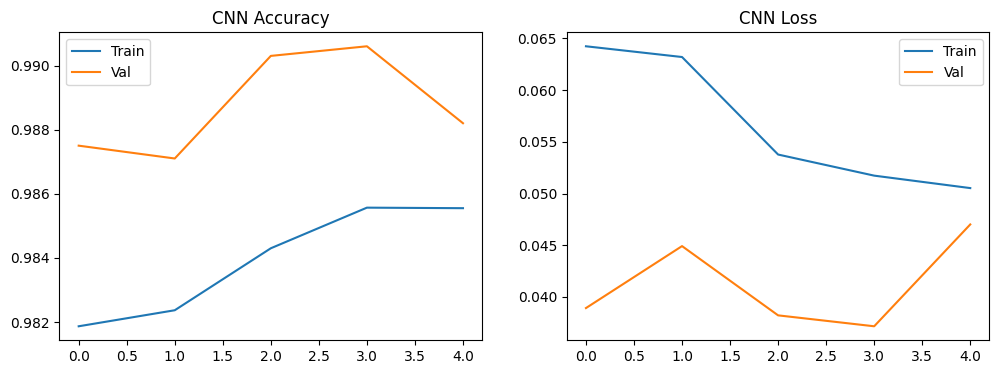

In [61]:
plot_training(history_cnn, "CNN")

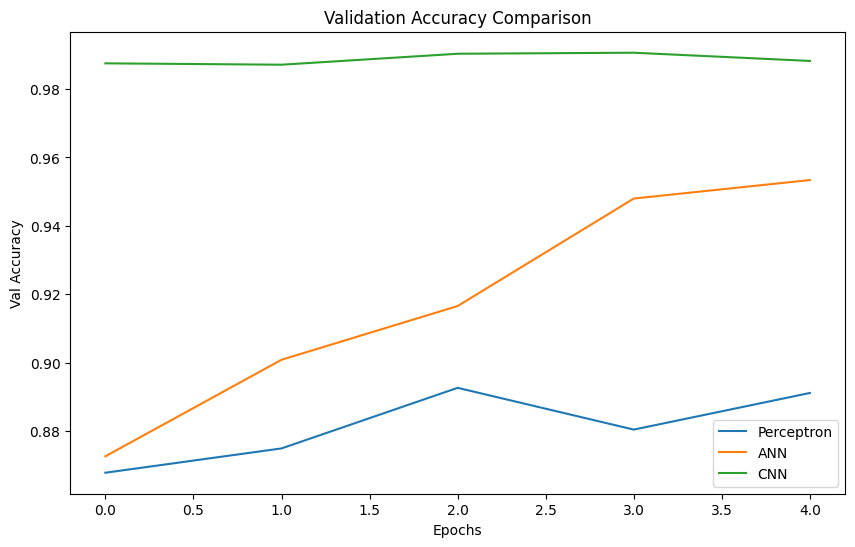

In [63]:

plt.figure(figsize=(10,6))
plt.plot(history.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [64]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


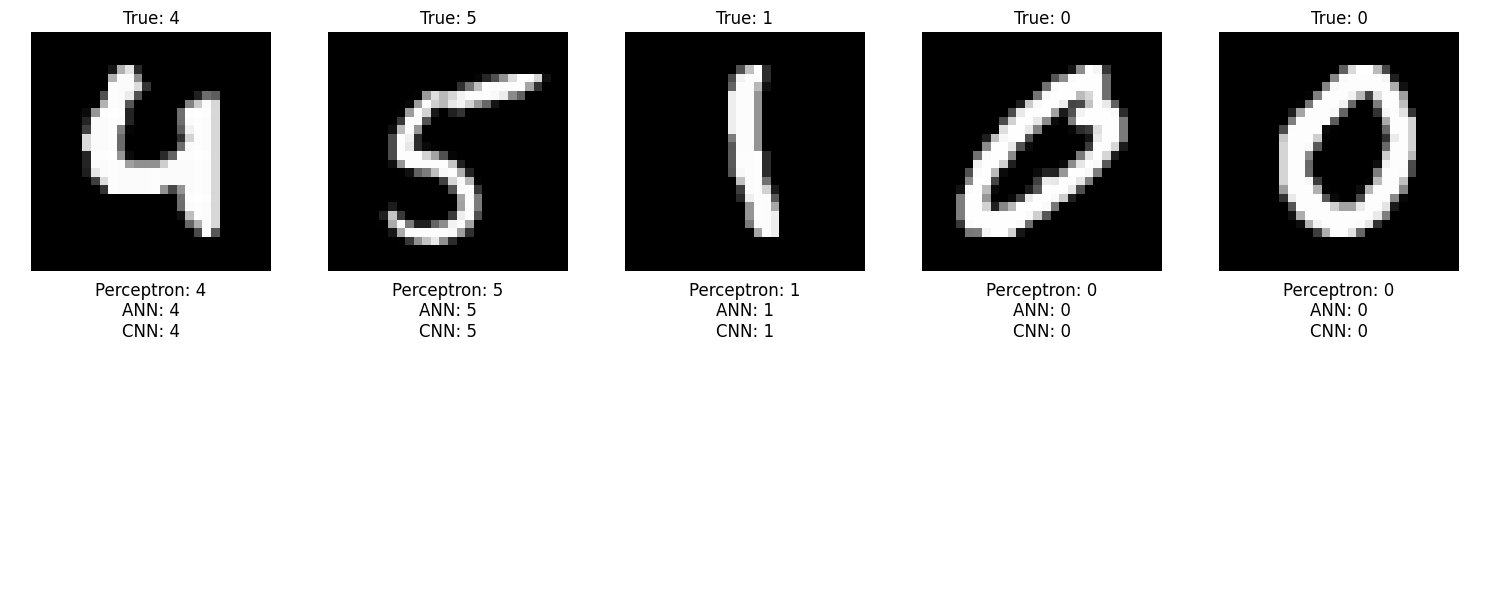

In [73]:
show_side_by_side([model, ann_model, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step


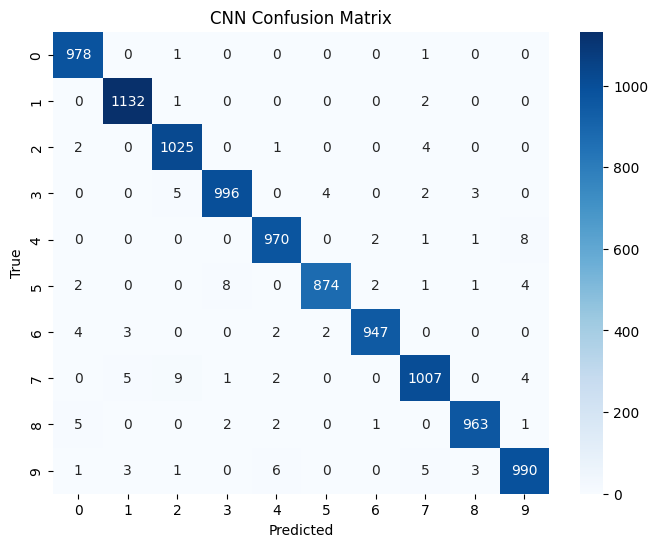

In [74]:

y_pred_cnn = np.argmax(cnn.predict(X_test_cnn), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


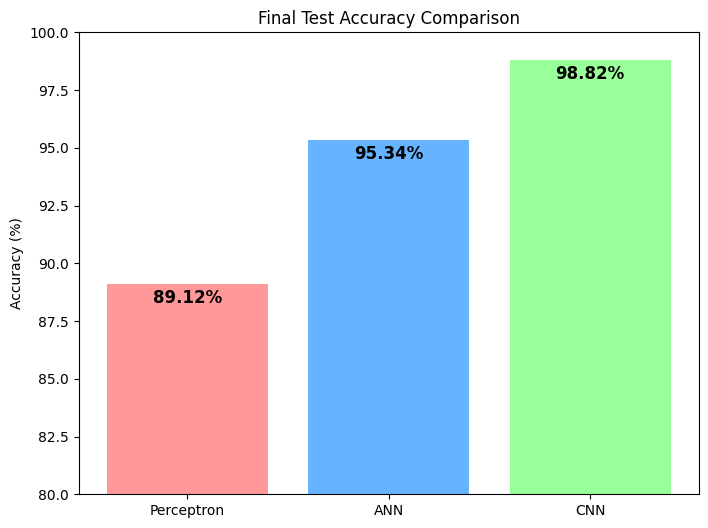

In [77]:
# Extract the accuracy from the cnn.evaluate() output list (index 1 is accuracy)
cnn_accuracy = acc_cnn[1] if isinstance(acc_cnn, list) else acc_cnn

final_accs = [acc*100, acc_ann*100, cnn_accuracy*100]
models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(8,6))
bars = plt.bar(models, final_accs, color=['#ff9999','#66b3ff','#99ff99'])
plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar, accuracy_val in zip(bars, final_accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-1, f"{accuracy_val:.2f}%",
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylim(80, 100)
plt.show()